In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load Data
df = pd.read_csv('Dataset.csv')

# 2. Extract numerical duration (e.g., "90 min" -> 90, "2 Seasons" -> 2)
def extract_duration(val):
    nums = re.findall(r'\d+', str(val))
    return int(nums[0]) if nums else 0

df['duration_num'] = df['duration'].apply(extract_duration)

# 3. Handle Release Year
df['release_year'] = df['release_year'].fillna(2010)

# 4. Select our features for clustering
# We only use numerical features for K-Means
X = df[['release_year', 'duration_num']].copy()

print(f"Data ready for clustering! Shape: {X.shape}")
print(X.head())

Data ready for clustering! Shape: (8790, 2)
   release_year  duration_num
0          2020            90
1          2021             1
2          2021             1
3          2021            91
4          1993           125


In [2]:
# 1. Calculate inertia for K=1 to K=10
inertia = []
K_range = range(1, 11)

for k in K_range:
    # We set random_state for reproducibility
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# 2. Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--')
plt.title('The Elbow Method: Finding the Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-cluster sum of squares)')
plt.xticks(K_range)
plt.show()

NameError: name 'X_scaled' is not defined

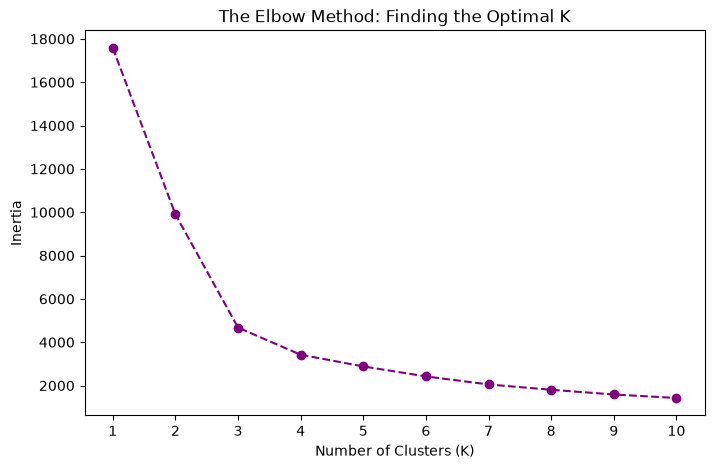

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Load and Prepare Data
df = pd.read_csv('Dataset.csv')

def extract_duration(val):
    nums = re.findall(r'\d+', str(val))
    return int(nums[0]) if nums else 0

df['duration_num'] = df['duration'].apply(extract_duration)
df['release_year'] = df['release_year'].fillna(2010)

# 2. Select Features
X = df[['release_year', 'duration_num']].copy()

# 3. Scale Features (This is what was missing!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow Method
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# 5. Plot
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='purple')
plt.title('The Elbow Method: Finding the Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(K_range)
plt.show()

In [4]:
# 1. Train K-Means with K=3
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_final.fit(X_scaled)

# 2. Add the cluster labels to our original dataframe
df['Cluster'] = kmeans_final.labels_

# 3. Let's see how many items are in each cluster
print("Items per Cluster:")
print(df['Cluster'].value_counts())

# 4. Let's look at the average Release Year and Duration for each cluster to understand them
cluster_summary = df.groupby('Cluster')[['release_year', 'duration_num']].mean()
print("\nAverage Characteristics of Each Cluster:")
print(cluster_summary)

Items per Cluster:
Cluster
1    5235
0    2971
2     584
Name: count, dtype: int64

Average Characteristics of Each Cluster:
         release_year  duration_num
Cluster                            
0         2017.076069      5.818243
1         2015.509265    102.007641
2         1987.578767    108.609589


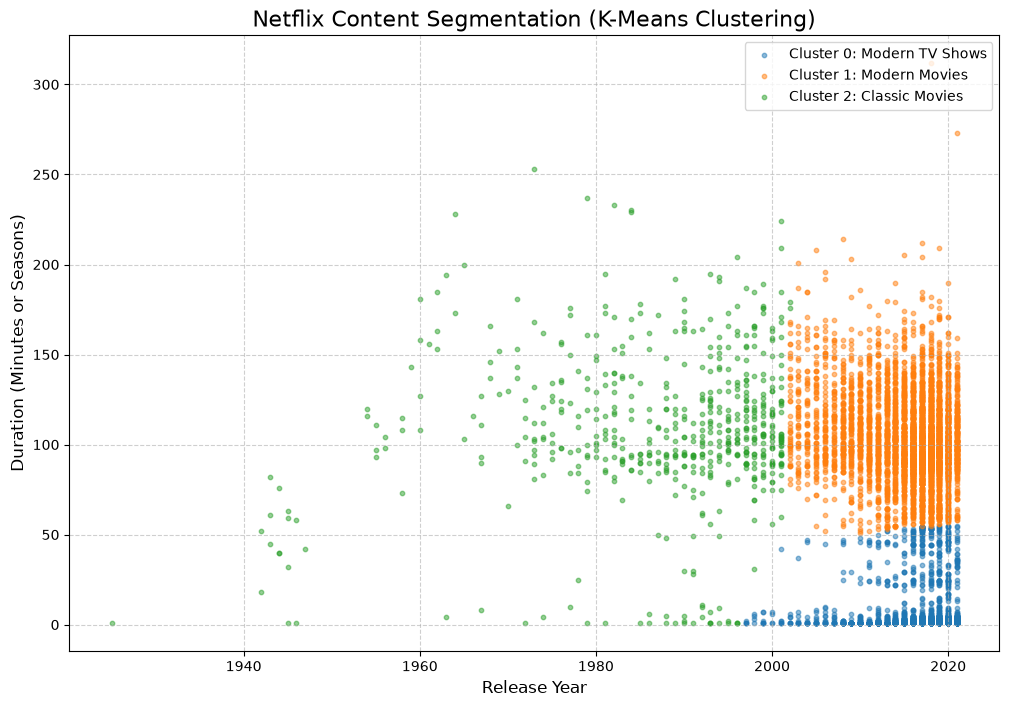

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set the figure size
plt.figure(figsize=(12, 8))

# 2. Define colors and labels for our 3 clusters
colors = ['#1f77b4', '#ff7f0e', '#2ca02c'] # Blue, Orange, Green
labels = ['Cluster 0: Modern TV Shows', 'Cluster 1: Modern Movies', 'Cluster 2: Classic Movies']

# 3. Plot each cluster
for i in range(3):
    cluster_data = df[df['Cluster'] == i]
    plt.scatter(
        cluster_data['release_year'], 
        cluster_data['duration_num'], 
        c=colors[i], 
        label=labels[i], 
        alpha=0.5,  # Transparency
        s=10        # Dot size
    )

# 4. Add titles and labels
plt.title('Netflix Content Segmentation (K-Means Clustering)', fontsize=16)
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Duration (Minutes or Seasons)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()